# 03 Generate the synthetic radar dataset

Random spheres (x, y, z, radius inside the ranges in 00_common) are simulated with the authors' simulator and calibrated with the simulated plane. Each sample is stored as phase robust features `[10, 31, 64]` (float16) plus its parameters, in shards of 250 samples under `outputs/data`.

* **Resumable:** finished shards are skipped, so if the run stops you just run this notebook again.
* **Time budget:** `BUDGET_HOURS` caps the run. The number of samples is chosen from the measured seconds per simulation (01_setup.json).
* **GPU:** this notebook holds the GPU for hours. Nothing else should use the GPU while it runs.

In [1]:
%run ./00_common.ipynb

C:\Users\Rey\anaconda3\envs\kolb\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


PROJECT  : C:\Users\Rey\Documents\Kolb_Radar_Project
FAKE_MODE: False
[mitsuba] Warning: Couldn't import the ipywidgets package. Installing this package is required for the system to properly log messages and print in Jupyter notebooks!


torch device: cuda
mitsuba variant: cuda_ad_rgb


Switched off Tx:  2
Switched off Rx:  10
torch 2.5.1+cu121 | device cuda
common ready


In [2]:
BUDGET_HOURS = float(os.environ.get('KOLB_BUDGET_HOURS', '4.0'))
MAX_SAMPLES  = int(os.environ.get('KOLB_MAX_SAMPLES', '20000'))
WORKER   = int(os.environ.get('KOLB_WORKER', '0'))     # several copies of this notebook can run at once on the GPU,
NWORKERS = int(os.environ.get('KOLB_NWORKERS', '1'))   # each one makes the shards with index % NWORKERS == WORKER
SHARD = 100
n_shards = max(1, MAX_SAMPLES // SHARD)
sec = json.load(open(RESULTS / '01_setup.json'))['seconds_per_sim'] if (RESULTS / '01_setup.json').exists() else 2.0
print(f'worker {WORKER}/{NWORKERS} | {sec:.2f} s per simulation (single process) | up to {n_shards * SHARD} samples | budget {BUDGET_HOURS} h')

worker 0/1 | 4.01 s per simulation (single process) | up to 100 samples | budget 4.0 h


In [3]:
t_start = time.time()
for s in range(n_shards):
    if s % NWORKERS != WORKER:
        continue
    path = DATA / f'shard_{s:04d}.npz'
    if path.exists():
        continue
    if time.time() - t_start > BUDGET_HOURS * 3600:
        log(f'03 worker {WORKER} stopped at shard {s}: time budget reached'); break
    rng = np.random.default_rng(1000 + s)            # each shard has its own seed, so resuming is deterministic
    P = sample_params(SHARD, rng)
    X = np.zeros((SHARD,) + FEAT_SHAPE, dtype=np.float16)
    if FAKE_MODE:
        for i in range(SHARD): X[i] = fake_features(P[i])
    else:
        for i in range(SHARD):
            X[i] = featurise(simulate(P[i]))
        utils.clean_dr()                              # free Dr.Jit kernel cache between shards
    tmp = DATA / f'tmp_{s:04d}.npz'
    np.savez_compressed(tmp, X=X, P=P); os.replace(tmp, path)   # atomic, so a half written shard is never loaded
    done = len(list(DATA.glob('shard_*.npz')))
    el = time.time() - t_start
    print(f'worker {WORKER}: shard {s} saved | {done * SHARD} samples total | {el/60:.1f} min elapsed', flush=True)
n_have = len(list(DATA.glob('shard_*.npz'))) * SHARD
save_json({'samples': n_have, 'seconds': time.time() - t_start, 'ranges_low': LOW.tolist(), 'ranges_high': HIGH.tolist(),
           'fake_mode': FAKE_MODE, 'workers': NWORKERS}, '03_dataset.json' if NWORKERS == 1 else f'03_dataset_worker{WORKER}.json')
log(f'03 worker {WORKER}: dataset now {n_have} samples')

saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\03_dataset.json
2026-10-27 01:00:39  03 worker 0: dataset now 5100 samples


(5100, 10, 31, 64) (5100, 4) feature range 5.960464477539063e-08 1.0


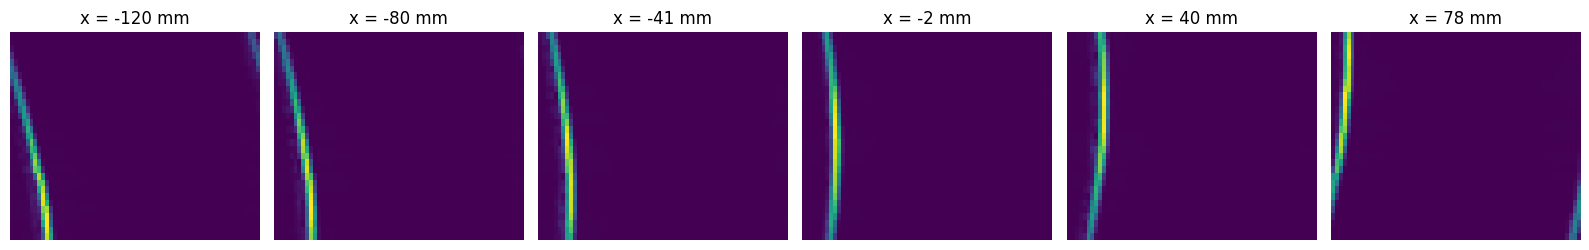

In [4]:
# Quick sanity check: features should change smoothly with x.
X, P = load_dataset()
print(X.shape, P.shape, 'feature range', float(X.min()), float(X.max()))
import matplotlib.pyplot as plt
order = np.argsort(P[:, 0])[::max(1, len(P)//6)][:6]
fig, ax = plt.subplots(1, len(order), figsize=(16, 2.6))
for a, i in zip(ax, order):
    a.imshow(X[i, 4].astype(np.float32), aspect='auto', origin='lower'); a.set_title(f'x = {P[i,0]*1000:.0f} mm'); a.axis('off')
plt.tight_layout(); plt.savefig(FIGS / '03_features_vs_x.png', dpi=110); plt.show()